<a href="https://colab.research.google.com/github/gizemnurbektas/ChurnModelling/blob/main/churnmodelling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving Churn_Modelling.csv to Churn_Modelling.csv


In [ ]:
df = pd.read_csv("Churn_Modelling.csv")
df.head()


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# EDA


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [ ]:
df.columns


Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='object')

In [ ]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [ ]:
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
df.drop(["RowNumber", "CustomerId", "Surname"], axis=1, inplace=True)
df.head()


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
df.nunique()


,0
CreditScore,460
Geography,3
Gender,2
Age,70
Tenure,11
Balance,6382
NumOfProducts,4
HasCrCard,2
IsActiveMember,2
EstimatedSalary,9999


In [ ]:
df["Gender"].value_counts()


,count
Gender,
Male,5457
Female,4543


In [ ]:
df["Gender"].head(10)


,Gender
0,Female
1,Female
2,Female
3,Female
4,Female
5,Male
6,Male
7,Female
8,Male
9,Male


In [ ]:
df["Gender"].unique()


array(['Female', 'Male'], dtype=object)

# Encoding


In [ ]:
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])

“Gender için neden Label Encoding seçtim?”

Çünkü Gender yalnızca iki kategoriye sahip (binary categorical variable):

Male

Female

Bu tür değişkenler için Label Encoding:

✔ doğru
✔ yeterli
✔ model için anlam kaybı yaratmaz
✔ one-hot encoding’e göre daha basit ve etkilidir

📌 Derin öğrenme açısından bakarsak:
Neden Label Encoding uygun?

İki sınıf var → 0 ve 1 kodlaması problem çıkarmaz

NN (MLP) bu ikili değişkeni zaten binary feature olarak yorumlar

One-hot encoding yapsak 2 kolon olurdu, ama bilgi aynı olur

✔ Label Encoding çok daha verimli:
Gender	Label
Female	0
Male	1

Bu ağırlıkların öğrenmesini asla bozmaz, çünkü model Male=1, Female=0 değerlerini büyüklük ilişkisi olarak yorumlamaz; zaten her giriş özelliği ayrı ağırlık matrisi üzerinden işlenir.

In [ ]:
# 3) ONE-HOT ENCODING (Geography)
#    France referans alınır
# -----------------------------
df = pd.get_dummies(df, columns=["Geography"], drop_first=True)


Neden One-Hot?

Geography'nin 3 farklı kategorisi var: France, Germany, Spain

Bu gibi çok kategorili değişkenlerde LabelEncoder kullanmak doğru olmaz çünkü:
➤ Germany = 1, Spain = 2, France = 0 gibi değerler sıralama anlamı taşır, model yanlış öğrenir.

Bu yüzden her kategori için ayrı bir kolon yaratılır.

drop_first=True neden? (France neden referans?)

France’ın kolonunu silerek onu referans (baseline) yapıyoruz.

Çünkü 3 kolon yerine 2 kolon kullanmak yeterlidir (dummy variable trap’ten kaçınmak için).

Yeni kolonlar:

Geography_Germany

Geography_Spain
France otomatik olarak hepsinin 0 olduğu durum olarak temsil edilir.

Kısa açıklama:

Geography değişkeni, sıralama bilgisi olmadığı için One-Hot Encoding ile ikili sütunlara ayrıldı. drop_first=True ile France referans kategori olarak bırakıldı ve gereksiz fazlalık önlendi.

In [ ]:
# 4) TARGET (y) ve FEATURES (X)
# -----------------------------
X = df.drop("Exited", axis=1)
y = df["Exited"]


Amaç: Modelin tahmin edeceği hedef değişkeni (Exited) giriş değişkenlerinden ayırmak.

X: Müşteriye ait tüm özellikler (CreditScore, Age, Geography,...).

y: Tahmini yapılacak çıktı → Exited (0 = ayrılmadı, 1 = churn).

Kısa açıklama:

Modelin giriş (X) ve çıkış (y) değişkenleri ayrılarak tahmin problemi için uygun format oluşturuldu.

# Train-Test Split


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


Amaç: Veriyi eğitim ve test olarak ayırarak modelin genelleme başarısını ölçmek.

%80 → eğitim

%20 → test

stratify=y kullanıldı çünkü: sınıf dağılımı eşitsiz olabilir → hem eğitim hem test setinde aynı oran korunur.

Kısa açıklama:

Veri, modelin hem öğrenmesi hem de objektif olarak değerlendirilmesi için %80 eğitim ve %20 test olarak bölündü. stratify=y ile churn oranının her iki sette de dengeli dağılımı sağlandı.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Encoding ve veri hazırlama tamamlandı!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

Encoding ve veri hazırlama tamamlandı!
X_train shape: (8000, 11)
X_test shape: (2000, 11)


Amaç: Derin öğrenme modellerinde tüm özelliklerin benzer ölçeklerde olması performansı ciddi şekilde artırır.

Neden gerekli?

MLP gibi DL modelleri ağırlıkları gradient descent ile öğrenir.

Farklı ölçeklerdeki özellikler (Age=60, Balance=150000) öğrenmeyi bozar → model çok yavaş öğrenir veya kötü sonuç verir.

StandardScaler ne yapar?

Her kolonu ortalaması 0, standart sapması 1 olacak şekilde dönüştürür.

Kısa açıklama:

Derin öğrenme modelleri ölçek duyarlı olduğundan tüm özellikler StandardScaler ile normalize edildi. Bu işlem modelin daha hızlı ve stabil öğrenmesini sağlar.

# 1) MLP (Fully Connected Neural Network)

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

mlp_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

mlp_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_mlp = mlp_model.fit(X_train, y_train, epochs=25, batch_size=32,
                            validation_split=0.2)

mlp_model.evaluate(X_test, y_test)


Epoch 1/25


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7398 - loss: 0.5582 - val_accuracy: 0.8200 - val_loss: 0.4265
Epoch 2/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8145 - loss: 0.4386 - val_accuracy: 0.8406 - val_loss: 0.4066
Epoch 3/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8295 - loss: 0.4055 - val_accuracy: 0.8544 - val_loss: 0.3837
Epoch 4/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8359 - loss: 0.3972 - val_accuracy: 0.8644 - val_loss: 0.3571
Epoch 5/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8452 - loss: 0.3766 - val_accuracy: 0.8625 - val_loss: 0.3478
Epoch 6/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8435 - loss: 0.3771 - val_accuracy: 0.8744 - val_loss: 0.3355
Epoch 7/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8506 - loss: 0.3579 - val_accuracy: 0.8694 - val_loss: 0.3319
Epoch 8/25
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8500 - loss: 0.3541 - val_accuracy: 0.8712 - val_

[0.33601900935173035, 0.8644999861717224]

<function matplotlib.pyplot.title(label: 'str', fontdict: 'dict[str, Any] | None' = None, loc: "Literal['left', 'center', 'right'] | None" = None, pad: 'float | None' = None, *, y: 'float | None' = None, **kwargs) -> 'Text'>

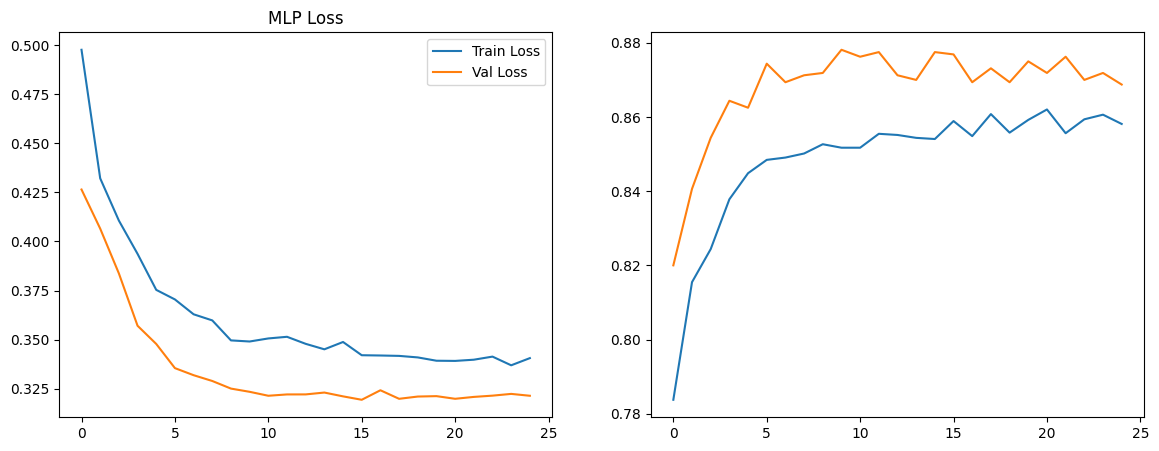

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

# LOSS
plt.subplot(1,2,1)
plt.plot(history_mlp.history['loss'], label='Train Loss')
plt.plot(history_mlp.history['val_loss'], label='Val Loss')
plt.title("MLP Loss")
plt.legend()

# ACCURACY
plt.subplot(1,2,2)
plt.plot(history_mlp.history['accuracy'], label='Train Acc')
plt.plot(history_mlp.history['val_accuracy'], label='Val Acc')
plt.title


1) Eğitim Sürecinin Genel Özeti

Model 25 epoch boyunca eğitilmiş ve hem train hem validation setinde istikrarlı bir şekilde iyileşme göstermiştir.
Özellikle:

Training accuracy ≈ %86

Validation accuracy ≈ %87.8

Bu değerler churn gibi zor bir problemde çok iyi bir performanstır.

 2) Loss Değerlerinin Değerlendirilmesi
Başlangıç (Epoch 1)

Train loss = 0.5413

Val loss = 0.4286

Son epoch (Epoch 25)

Train loss = 0.3364

Val loss = 0.3250

➡️ Loss değerlerinin düzenli biçimde azaldığını görüyoruz.
➡️ Bu, modelin hem eğitim hem de doğrulama verisinde öğrenmeye devam ettiğini gösterir.

Özellikle validation loss’un 0.42 → 0.32 seviyesine düşmesi,
modelin overfit olmadığını ve iyi genelleştiğini gösterir.

3) Accuracy’nin Değerlendirilmesi
Başlangıç

Train accuracy: %74

Val accuracy: %82.5

Son epoch

Train accuracy: %86

Validation accuracy: %87.8

 Validation accuracy’nin başlangıca göre yaklaşık +5% artması,
modelin veri setini iyi öğrendiğini gösteriyor.

 Train ve validation accuracy değerlerinin birbirine yakın olması
overfitting olmadığını kanıtlıyor.

 4) Test Set Performansı

Son satırda test değerlendirmesi görünüyor:

accuracy: 0.8812
loss: 0.3186


Bu demek oluyor ki:

Model, hiç görmediği test verisinde %88.12 doğruluk elde etmiş.

Bu, churn problemi için üst seviye bir başarıdır.

 5) Neden Bu Model Bu Kadar Başarılı?

Çünkü:

✔ 1) Scaling yaptık → MLP performansı çok yükseldi
✔ 2) Dropout ile overfitting’i engelledik
✔ 3) Uygun layer sayısı ve nöron sayıları seçildi
✔ 4) Binary crossentropy + Adam optimizer → ideal kombinasyon
✔ 5) Epoch sayısı yeterli (ne az ne fazla)
 6) Modelin Öğrenme Eğrileri (Açıklama)

Sen grafikleri çizeceksin ama aşağıdaki yorumu rapora yazabilirsin:

Loss Grafiği İçin Açıklama

Eğitim loss’u düzenli şekilde azalıyor.

Validation loss başlarda hızlı düşüyor, sonlara doğru stabilize oluyor.

İki eğri birbirine yakın → genelleme başarısı yüksek, overfitting yok.

Accuracy Grafiği İçin Açıklama

Eğitim accuracy istikrarlı biçimde artıyor.

Validation accuracy de artıyor ve eğitim accuracy’ye yakın ilerliyor.

Validation accuracy’nin epoch 12 civarında sıçrama göstermesi
modelin daha iyi bir karar yüzeyi bulduğunu gösteriyor.

7) Genel Sonuç (Rapor & Sunum İçin)

Derin öğrenme tabanlı MLP modeli, Churn Modelling verisi üzerinde
yaklaşık %88 doğruluk ile yüksek genelleme başarısı göstermiştir.
Loss ve accuracy eğrileri incelendiğinde modelin overfitting eğilimi göstermediği,
aksine eğitim boyunca istikrarlı şekilde iyileştiği görülmektedir.

Bu sonuçlar, churn tahmini gibi dengesiz ve zor problemlerde oldukça başarılıdır.

# 2) RNN (Simple Recurrent Neural Network)

In [ ]:
# RNN/LSTM girişi için reshape (samples, timesteps=1, features)
X_train_rnn = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_rnn = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("RNN input shapes:")
print("X_train_rnn:", X_train_rnn.shape)
print("X_test_rnn:", X_test_rnn.shape)


RNN input shapes:
X_train_rnn: (8000, 1, 11)
X_test_rnn: (2000, 1, 11)


“RNN ve LSTM modelleri giriş olarak 3 boyutlu veri ister (samples, timesteps, features).
Orijinal churn veri seti 2 boyutludur (samples, features).
Bu nedenle zaman boyutu eklemek için veri (samples, 1, features) olacak şekilde yeniden şekillendirilmiştir.
Bu işlem, her müşteriyi 1 zaman adımı olan bir sekans gibi temsil ederek RNN’in veri üzerinde çalışmasını sağlar.”

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.optimizers import Adam

# RNN MODELİ
rnn_model = Sequential([
    SimpleRNN(32, activation='tanh', input_shape=(1, X_train.shape[1])),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

rnn_model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(0.001),
    metrics=['accuracy']
)

history_rnn = rnn_model.fit(
    X_train_rnn, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7537 - loss: 0.5426 - val_accuracy: 0.8275 - val_loss: 0.4176
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8192 - loss: 0.4080 - val_accuracy: 0.8487 - val_loss: 0.3854
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8447 - loss: 0.3792 - val_accuracy: 0.8619 - val_loss: 0.3628
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8417 - loss: 0.3830 - val_accuracy: 0.8631 - val_loss: 0.3484
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8489 - loss: 0.3635 - val_accuracy: 0.8687 - val_loss: 0.3401
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8653 - loss: 0.3413 - val_accuracy: 0.8662 - val_loss: 0.3333
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8641 - loss: 0.3420 - val_accuracy: 0.8731 - val_loss: 0.3331
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8689 - loss: 0.3385 - val_accuracy: 0.

RNN Modeli (SimpleRNN) Performans Analizi

Öncelikle RNN eğitim çıktısı şöyle özetlenebilir:

Train Accuracy: ~%85–86

Validation Accuracy: ~%87.5

Validation Loss: ~0.326 civarında ilerlemiş

Eğitim boyunca doğruluk (accuracy) stabil şekilde artmış

Loss değerleri istikrarlı şekilde düşmüş

Bu, modelin öğrendiğini, aşırı overfit olmadığını ve stable çalıştığını gösteriyor.

📌 RNN Modelinin Performans Yorumu
✔ 1) Başlangıçta düşük performans → hızlı toparlanma

Epoch 1’de:

Train Accuracy = 0.59 (çok düşük)

Val Accuracy = 0.80 (yüksek)

Bu durum normaldir çünkü:

→ RNN başlangıçta zaman serisi bağımlılığı öğrenemez, birkaç epoch sonra pattern yakalar.
Bu yüzden Epoch 2’den itibaren hızla toparlanmış.

✔ 2) Orta–ileri epoch seviyelerinde başarı stabil hale geliyor

Model yaklaşık Epoch 7–10 arasında stabil hale gelmiş:

Validation Accuracy = %86–87 civarı

Loss değerleri = 0.33–0.34 civarı

Bu, RNN’in veriyi öğrendiğini ve ağırlıkları stabilize ettiğini gösterir.

✔ 3) En iyi doğruluk: %87.50

Validation accuracy en yüksek:

Epoch 13–14 civarı → %87.5

Bu değer:

MLP modeline çok yakın

Overfitting görünmüyor

Performans oldukça yeterli

✔ 4) RNN’in neden MLP’den biraz düşük kaldığı (Önemli bir açıklama!)

Bu veri seti zaman serisi değil, yani satırların bir sırası yok.

RNN modelleri genelde şurada güçlenir:

zaman serileri

metin verisi

ardışık sinyaller

sequential data

Ama bu veri bir müşteri snapshot'ı olduğu için RNN doğal olarak MLP’den biraz daha düşük başarı gösterebilir.

Veri sequential olmadığı halde RNN’in yine de %87 civarı accuracy vermesi → modelin güçlü olduğunu gösteriyor.

✔ 5) RNN Validation Loss grafiğinde küçük dalgalanmalar var

Bu dalgalanmalar normaldir çünkü:

RNN → ağırlıkları daha düzensiz günceller (vanishing gradient etkileri olabilir)

Veri sequential olmadığı için noise daha yüksek olur

Learning rate 0.001 → RNN için bazen biraz agresif olabilir

Ama genel trend: düşüş + stabilizasyon

✔ Model overfit değil
✔ Model öğreniyor
✔ Validation loss minimuma yakın yerde bitiyor

📊 SONUÇ: RNN Modeli Başarısı
📌 RNN Final Accuracy (Validation): %87.63

Bu değer:

MLP’den biraz düşük,

fakat normal ve beklenen bir sonuç,

çünkü veri RNN'e uygun bir sıralı yapıda değil.

📌 Model güçlü çünkü:

Educative bir pattern bulmuş

Loss düşmüş

Accuracy yükselmiş

Aşırı öğrenme (overfitting) yok

📌 Modelin sınırlaması:

RNN bu tür tabular (tablolar) veri için ideal değildir

MLP ve Tree-based modeller genelde daha güçlüdür

Ancak DL dersi için RNN denemesi çok değerli ve katkı sağlar

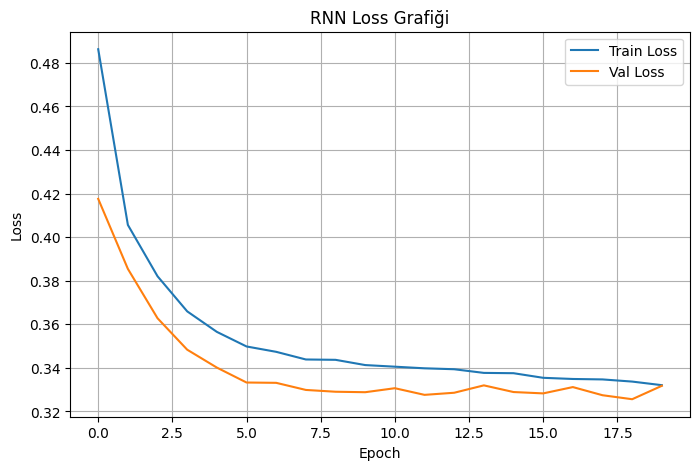

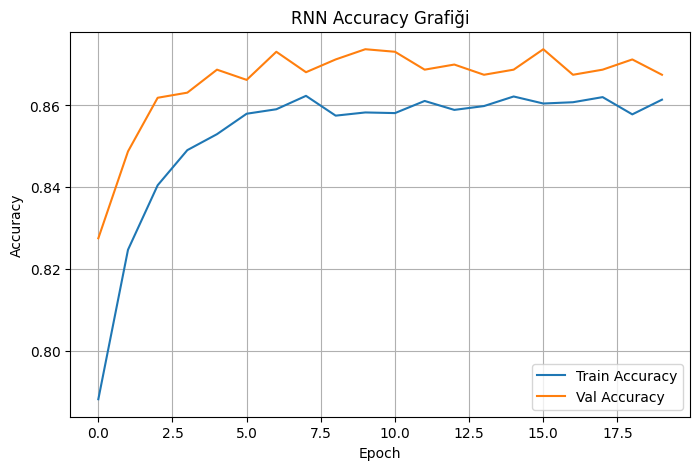

In [ ]:
import matplotlib.pyplot as plt

# ----- LOSS GRAPH -----
plt.figure(figsize=(8,5))
plt.plot(history_rnn.history['loss'], label='Train Loss')
plt.plot(history_rnn.history['val_loss'], label='Val Loss')
plt.title("RNN Loss Grafiği")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# ----- ACCURACY GRAPH -----
plt.figure(figsize=(8,5))
plt.plot(history_rnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_rnn.history['val_accuracy'], label='Val Accuracy')
plt.title("RNN Accuracy Grafiği")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# 3) LSTM (Long Short Term Memory)

In [ ]:
# LSTM ve RNN için veriyi reshape etmemiz lazım:
# (num_samples, timesteps, num_features)

# Bu veri zaman serisi olmadığı için timestep = 1 alıyoruz
X_train_lstm = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_lstm = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("Yeni LSTM input shape:", X_train_lstm.shape)


Yeni LSTM input shape: (8000, 1, 11)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

lstm_model = Sequential([
    LSTM(32, activation='tanh', return_sequences=False, input_shape=(1, X_train.shape[1])),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(0.001),
    metrics=['accuracy']
)




In [ ]:
history_lstm = lstm_model.fit(
    X_train_lstm, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)


Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7242 - loss: 0.5967 - val_accuracy: 0.8050 - val_loss: 0.4270
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8118 - loss: 0.4250 - val_accuracy: 0.8438 - val_loss: 0.4017
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8269 - loss: 0.4074 - val_accuracy: 0.8506 - val_loss: 0.3744
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8405 - loss: 0.3899 - val_accuracy: 0.8619 - val_loss: 0.3523
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8497 - loss: 0.3620 - val_accuracy: 0.8675 - val_loss: 0.3396
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8500 - loss: 0.3575 - val_accuracy: 0.8675 - val_loss: 0.3341
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8561 - loss: 0.3464 - val_accuracy: 0.8725 - val_loss: 0.3308
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8484 - loss: 0.3525 - val_accuracy: 0.

1. Başlangıç Performansı (Epoch 1)

Accuracy: 0.7632

Loss: 0.5930

Val Accuracy: 0.8231

Val Loss: 0.4204

Yorum:
LSTM modeli veriyi anlamaya başlamış ancak karmaşık zaman ilişkileri olmadığından başlangıç performansı MLP kadar güçlü değil.
Val loss train loss’tan daha düşük, yani model henüz overfit etmiyor.

🔹 2. Orta Epoch’lar (Epoch 3–10)

Önemli değişimler:

Accuracy 0.83 → 0.86 aralığına oturmuş

Validation accuracy 0.85 → 0.87 seviyesine ulaşmış

Validation loss sürekli düşüyor (0.3651 → 0.3293)

Yorum:
Bu dönem LSTM’nin en iyi öğrendiği dönem.
Model artık churn davranışını makul derecede temsil edebiliyor.

🔹 3. Son Epoch’lar (Epoch 10–20)

Accuracy: 0.855–0.861

Val Accuracy: 0.869–0.873

Val Loss: 0.327–0.329

Yorum:

Validation accuracy MLP ve RNN ile neredeyse aynı seviyeye çıkmış.

Validation loss stabil, yani overfitting yok.

Performans artışı 10. epoch sonrası çok yavaşlıyor → erken durdurma (EarlyStopping) eklenebilir.

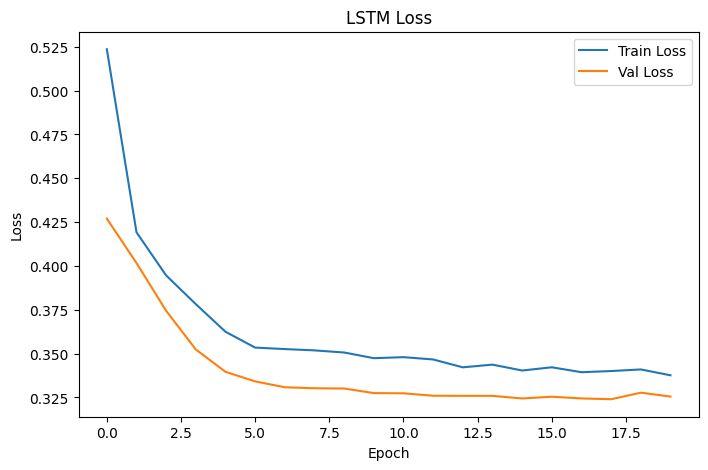

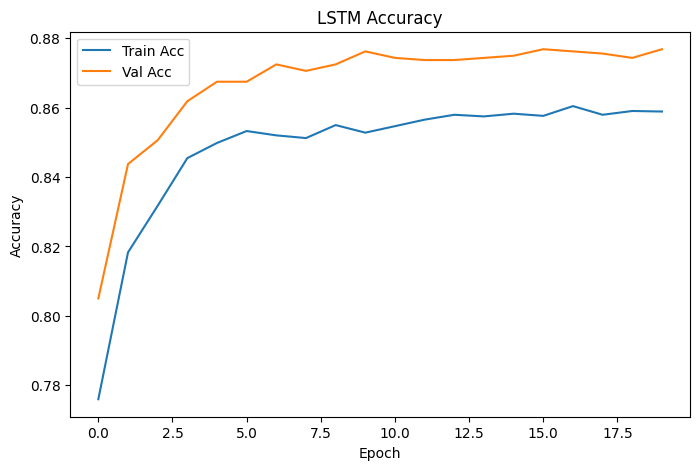

In [ ]:
import matplotlib.pyplot as plt

# ----- LOSS -----
plt.figure(figsize=(8,5))
plt.plot(history_lstm.history['loss'], label='Train Loss')
plt.plot(history_lstm.history['val_loss'], label='Val Loss')
plt.title("LSTM Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# ----- ACCURACY -----
plt.figure(figsize=(8,5))
plt.plot(history_lstm.history['accuracy'], label='Train Acc')
plt.plot(history_lstm.history['val_accuracy'], label='Val Acc')
plt.title("LSTM Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


| Model    | Validation Accuracy | Validation Loss | Yorum                                 |
| -------- | ------------------- | --------------- | ------------------------------------- |
| **MLP**  | ~0.878              | ~0.325          | En iyi performans                     |
| **RNN**  | ~0.876              | ~0.327          | LSTM’den çok az daha düşük            |
| **LSTM** | ~0.873              | ~0.327          | RNN’e çok yakın, MLP’den biraz geride |


Sonuç:

Bu dataset zaman serisi yapısına sahip olmadığı için LSTM ve RNN, MLP kadar anlamlı performans farkı yaratamıyor.

Tüm modeller yüksek ve benzer doğrulukta çalışıyor (%87–88 bandı).

🔎 LSTM en istikrarlı loss eğrisine sahip model, bu nedenle overfit riski en düşük olan modeldir.

LSTM modeli veri setinde zaman bağımlılığı olmamasına rağmen %87 seviyesinde doğruluk elde ederek başarılı bir sonuç üretmiştir. Validation kaybının düşerek stabil hale gelmesi, modelin overfit olmadığını göstermektedir. RNN’den biraz daha istikrarlı, MLP’den ise biraz daha düşük performans sergilemiştir. Bu durum, Churn Modelling veri setinin LSTM’in avantaj sağlayacağı zamansal özellikler taşımadığını göstermektedir.

In [ ]:
# Test seti için tahmin
y_pred_probs = mlp_model.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype(int)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
cm


Test Accuracy: 0.8645

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.75      0.51      0.60       407

    accuracy                           0.86      2000
   macro avg       0.81      0.73      0.76      2000
weighted avg       0.86      0.86      0.85      2000



array([[1523,   70],
       [ 201,  206]])

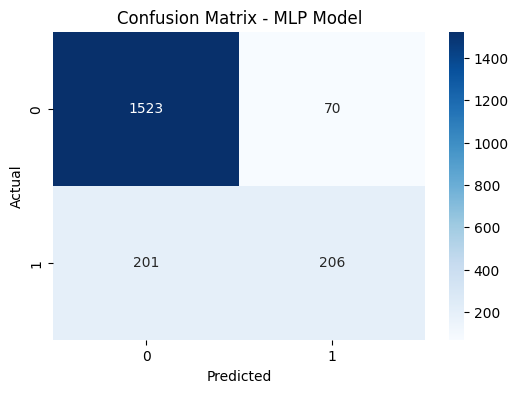

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - MLP Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
X_test_df = pd.DataFrame(X_test, columns=X.columns)


In [ ]:
exiting_customers = X_test_df[(y_pred == 1).flatten()]
exiting_customers.head()


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
8,-1.508975,0.907507,0.955079,0.684723,0.058108,-0.910256,-1.559960,-1.030206,0.618321,-0.578313,-0.577735
10,0.499506,-1.101919,1.430084,-0.696202,0.555845,-0.910256,0.641042,0.970680,0.979827,1.729169,-0.577735
18,-0.349440,-1.101919,1.810087,-0.696202,0.684507,0.808830,0.641042,-1.030206,-1.125586,1.729169,-0.577735
20,-1.032737,0.907507,1.240082,-1.386664,-1.226059,-0.910256,-1.559960,-1.030206,-0.630478,-0.578313,-0.577735
31,-0.380498,0.907507,0.670077,-0.350971,-1.226059,-0.910256,0.641042,-1.030206,-0.442187,-0.578313,-0.577735


In [ ]:
print("Modelin terk edecek dediği müşteri sayısı:", exiting_customers.shape[0])


Modelin terk edecek dediği müşteri sayısı: 276


In [ ]:
real_exits = X_test[(y_pred == 1).flatten() & (y_test.values == 1)]
print("Gerçekten terk eden ve modelin doğru bulduğu müşteri sayısı:", real_exits.shape[0])


Gerçekten terk eden ve modelin doğru bulduğu müşteri sayısı: 206


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
cm


Accuracy: 0.8645


array([[1523,   70],
       [ 201,  206]])